# Lesson 02 extension — DQN with Ray RLlib

**Driving question:** Which parts of our handwritten DQN can a reinforcement-learning library manage for us?

Run this companion after [the main DQN notebook](../../lessons/lesson02_dqn/Lesson_02_DQN_Gymnasium.ipynb). It is a standalone optional extension beyond the core 60-minute lesson. It uses the same **CartPole-v1**, **4 → 64 → 64 → 2** architecture, training seed 7, and 20 evaluation reset seeds.

You will configure DQN, train it through RLlib, evaluate frozen policies, and watch before/after behavior. RLlib provides the replay and learning machinery; Gymnasium still defines the environment.

**Reward reminder:** CartPole gives **+1 per step**, including the failure step. Failure ends future rewards; there is no additional failure penalty. The 500-step wrapper limit ends an episode by truncation. Total episode reward equals episode length in this environment.

> **Prediction:** Will changing the implementation library alone guarantee a better policy? What must we measure to answer fairly?

## 1. Setup
Use the workshop environment with its pinned **Ray RLlib 2.59.0** and PyTorch. No GPU or remote workers are required. Run **Restart Kernel and Run All**. This notebook starts a local Ray runtime when needed and stops the runtime it started after training and evaluation.

Run from the repository with:

```bash
uv run --no-sync jupyter lab src/lessons/lesson02_dqn/Lesson_02_DQN_RLlib.ipynb
```

For a separate environment, install `ray[rllib,tune,default]==2.59.0`, `torch`, `gymnasium[classic-control]`, `numpy`, `matplotlib`, and `jupyterlab`. Later Ray releases may change these APIs.

In [1]:
from pathlib import Path
from copy import deepcopy
import csv
import os
import time

os.environ.setdefault("SDL_VIDEODRIVER", "dummy")
os.environ.setdefault("SDL_AUDIODRIVER", "dummy")
import gymnasium as gym
import numpy as np
import torch
import ray
from ray.rllib.algorithms.dqn import DQNConfig
from ray.rllib.core.columns import Columns
from ray.rllib.core.rl_module.default_model_config import DefaultModelConfig
from ray.rllib.utils.metrics import NUM_ENV_STEPS_SAMPLED_LIFETIME
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, Image, display

candidates = [Path.cwd(), *Path.cwd().parents]
module_root = next((p for p in candidates if (p / "lessons").is_dir()), None)
if module_root is None:
    repo_root = next((p for p in candidates if (p / "src/lessons").is_dir()), None)
    if repo_root is None:
        raise RuntimeError("Open the notebook from inside the workshop repository")
    module_root = repo_root / "src"
OUTPUT = module_root / "outputs/lesson02_rllib"
OUTPUT.mkdir(parents=True, exist_ok=True)
torch.set_num_threads(1)
TRAIN_SEED = 7
EVAL_SEEDS = tuple(range(2026, 2046))
TRAINING_STEPS = 40000
MAX_ITERATIONS = 40
print("Ray:", ray.__version__, "PyTorch:", torch.__version__, "Gymnasium:", gym.__version__)
print("Outputs:", OUTPUT)

Ray: 2.59.0 PyTorch: 2.11.0+cu128 Gymnasium: 1.2.2
Outputs: /workspace/src/outputs/lesson02_rllib


## 2. Same Q-network, library-managed learning

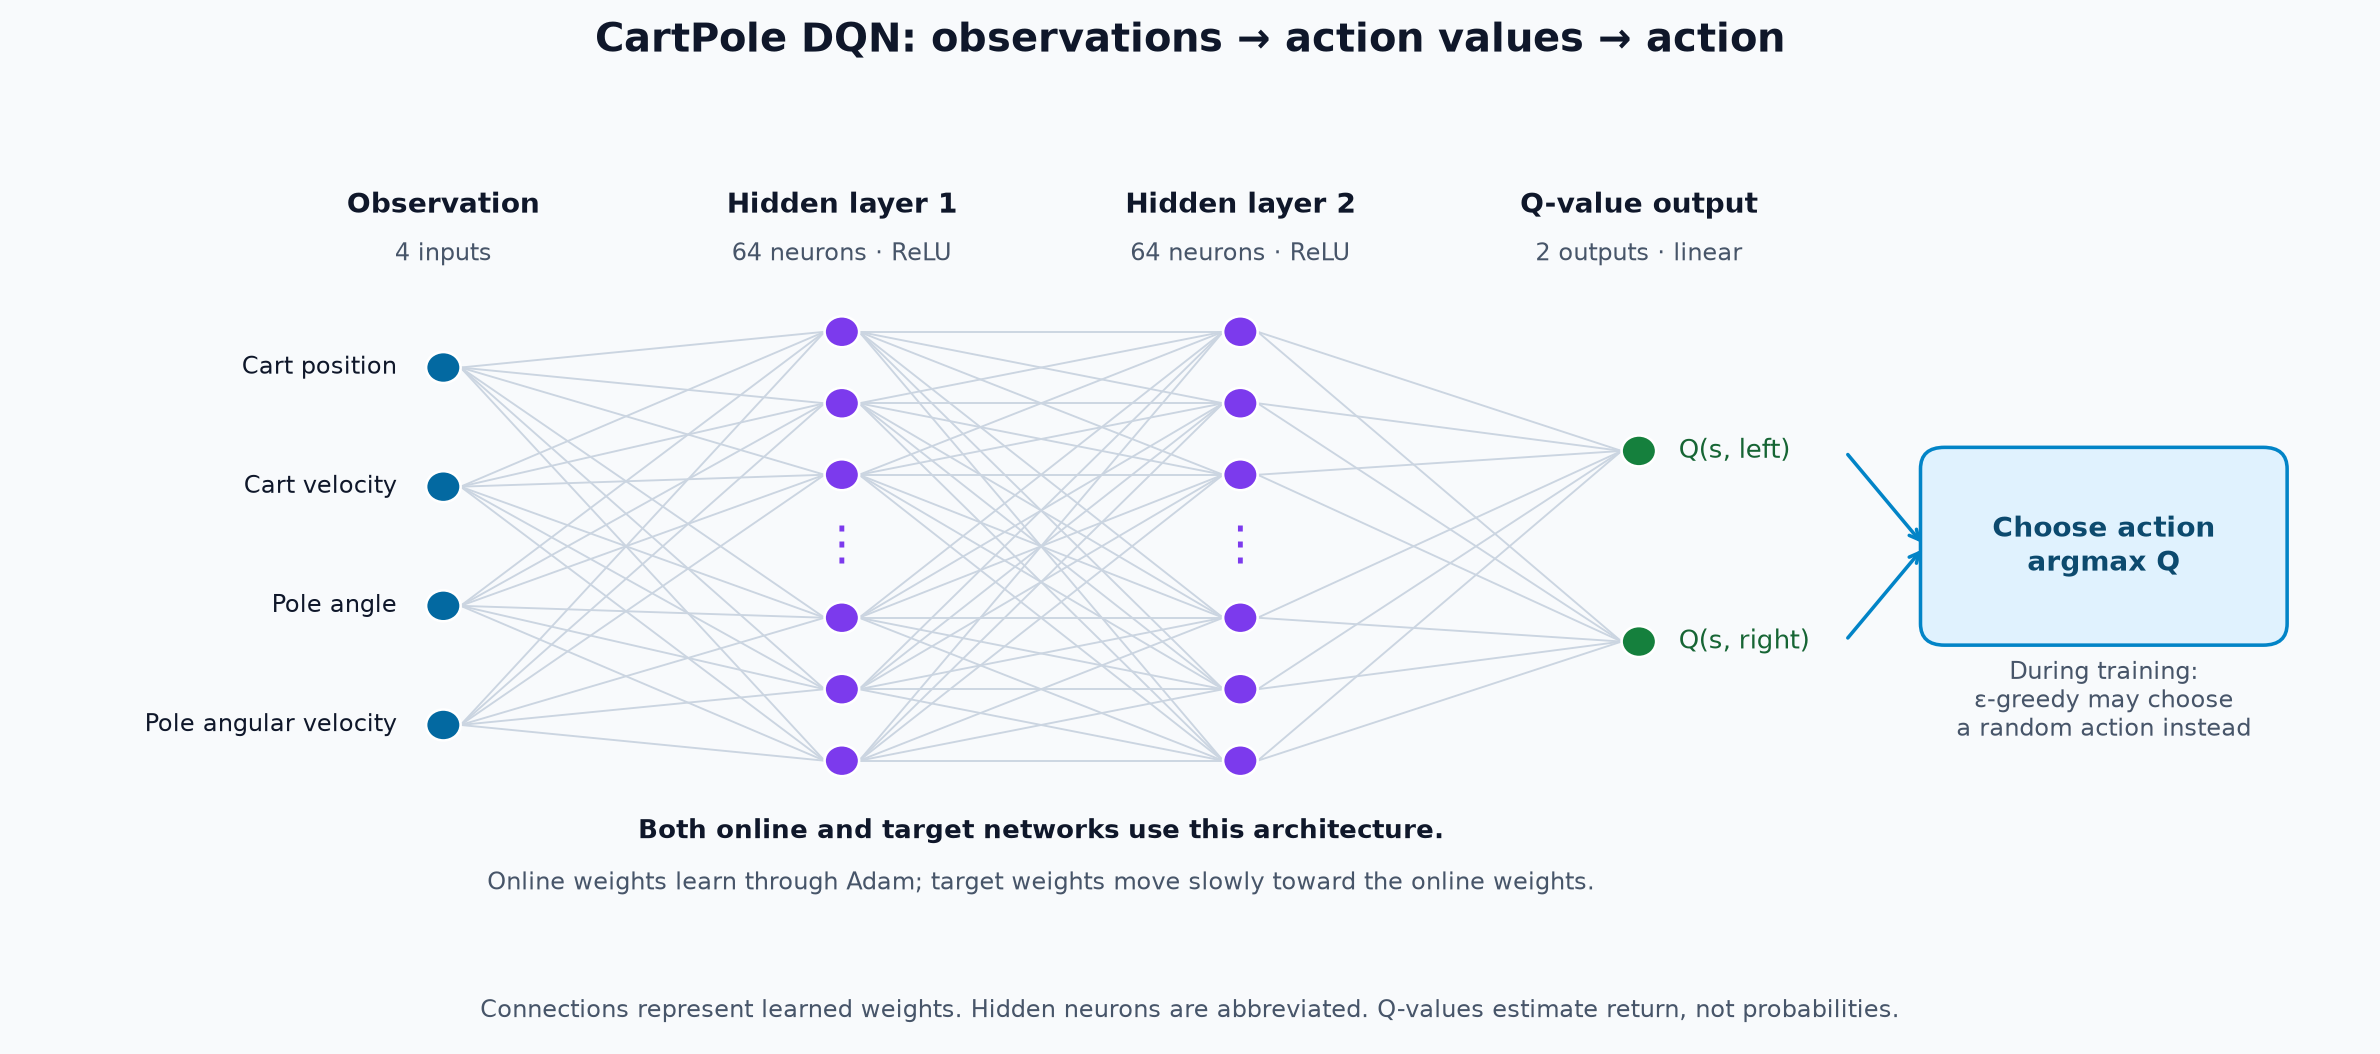

RLlib calls its neural component an **RLModule**. The configuration below uses a 64-unit encoder and a 64-unit Q head, producing the same two-hidden-layer shape as the handwritten network. With dueling disabled, this head predicts the two action values directly.

| Handwritten component | RLlib configuration or API |
|---|---|
| Environment | `.environment("CartPole-v1")` |
| Hidden layers | `DefaultModelConfig` |
| Experience collection | Local `EnvRunner` |
| Replay memory | Uniform `EpisodeReplayBuffer` |
| Bellman target and Adam updates | DQN `Learner`, configured with `.training(...)` |
| Exploration | Step-based `epsilon` schedule |
| Target network | Hard synchronization every 500 sampled steps |
| Greedy evaluation | `RLModule.forward_inference(...)` |

**Important comparison limits:** This is the same basic DQN idea, not an exact reproduction. RLlib samples replay from episodes and performs approximately one 128-transition update per four new steps here; the handwritten notebook updates every step. RLlib uses a hard target copy here, while the main notebook uses soft updates. Initializers, optimizer details, and RNG consumption also differ. Compare learning behavior, not bit-for-bit outputs or library speed from one run.

We explicitly disable RLlib's default **Double DQN** and **dueling** extensions and choose uniform replay. `num_atoms=1` and `n_step=1` keep the scalar, one-step target from the main lesson.

**Predict:** What does setting `num_env_runners=0` mean? It selects a local runner, rather than removing the environment.

In [2]:
config = (
    DQNConfig()
    .environment("CartPole-v1")
    .framework("torch")
    .env_runners(num_env_runners=0, rollout_fragment_length=4)
    .learners(num_learners=0, num_gpus_per_learner=0)
    .training(
        gamma=0.99,
        lr=0.0005,
        train_batch_size_per_learner=128,
        num_steps_sampled_before_learning_starts=1000,
        replay_buffer_config={"type": "EpisodeReplayBuffer", "capacity": 10000},
        epsilon=[(0, 1.0), (20000, 0.05)],
        training_intensity=32,  # 32 replayed transitions per new environment step.
        target_network_update_freq=500,
        tau=1.0,  # Hard copy at each synchronization, rather than a soft update.
        td_error_loss_fn="huber",
        grad_clip=10.0,
        grad_clip_by="global_norm",
        dueling=False,
        double_q=False,
        num_atoms=1,
        n_step=1,
    )
    .rl_module(model_config=DefaultModelConfig(
        fcnet_hiddens=[64], fcnet_activation="relu",
        head_fcnet_hiddens=[64], head_fcnet_activation="relu",
    ))
    .reporting(min_sample_timesteps_per_iteration=1000, min_time_s_per_iteration=0)
    .debugging(seed=TRAIN_SEED, log_level="ERROR")
)
config.validate()
print("DQN configuration validated.")

2026-11-10 05:00:02,424	WARNING algorithm_config.py:5160 -- You are running DQN on the new API stack! This is the new default behavior for this algorithm. If you don't want to use the new API stack, set `config.api_stack(enable_rl_module_and_learner=False,enable_env_runner_and_connector_v2=False)`. For a detailed migration guide, see here: https://docs.ray.io/en/master/rllib/new-api-stack-migration-guide.html


DQN configuration validated.


## 3. Evaluate through the RLModule API
The new RLlib API uses `algo.get_module()` and `forward_inference`, which selects greedy actions for this DQN module. We do not call `algo.train()` during evaluation. Gymnasium rollouts stop on either flag; RLlib handles the separate terminal mask in its training targets.

Random, untrained, and trained policies use the **same 20 reset seeds** as the main notebook. The random policy has an independent action RNG. Standard deviation below describes differences between evaluation episodes, not between independently trained agents.

In [3]:
def greedy_action(module, observation):
    with torch.no_grad():
        batch = {Columns.OBS: torch.as_tensor(observation, dtype=torch.float32).unsqueeze(0)}
        output = module.forward_inference(batch)
        return int(output[Columns.ACTIONS].reshape(-1)[0].item())

def evaluate(module=None, *, seeds=EVAL_SEEDS):
    returns, lengths, caps = [], [], []
    env = gym.make("CartPole-v1")
    try:
        for seed in seeds:
            observation, _ = env.reset(seed=int(seed))
            rng = np.random.default_rng(seed + 10000)
            total, steps = 0.0, 0
            while True:
                action = int(rng.integers(2)) if module is None else greedy_action(module, observation)
                observation, reward, terminated, truncated, _ = env.step(action)
                total += reward
                steps += 1
                if terminated or truncated:
                    returns.append(total)
                    lengths.append(steps)
                    caps.append(bool(truncated and not terminated))
                    break
    finally:
        env.close()
    return {"mean_return": float(np.mean(returns)),
            "std_return": float(np.std(returns, ddof=1)),
            "mean_length": float(np.mean(lengths)),
            "time_limit_fraction": float(np.mean(caps)), "episodes": len(returns)}

## 4. Build, train, and freeze
`config.build_algo()` constructs the environment runner, online/target networks, replay buffer, and learner. Each `algo.train()` call collects experience and performs learning; an **iteration is not an episode**.

Progress is measured in sampled environment steps. There are at most 40 iterations, with at least 1,000 new sampled steps requested per iteration. We stop when the 40,000-step target is reached; library batching may overshoot this target. Startup and RLlib orchestration add overhead relative to the small handwritten loop. Expect several minutes on a CPU.

The initial module is copied before training. After training, we copy the learned module for evaluation and visualization, then clean up the algorithm and any Ray runtime started here. An existing Ray session is left running.

**Before executing:** Predict how evaluation return will differ from exploratory training return. Is one library run enough to compare algorithms?

In [4]:
algo = None
started_ray_here = not ray.is_initialized()
history = []
started = time.perf_counter()
try:
    if started_ray_here:
        ray.init(num_cpus=2, include_dashboard=False, log_to_driver=False,
                 object_store_memory=100 * 1024 * 1024)
    algo = config.build_algo()
    initial_module = deepcopy(algo.get_module()).eval()
    print(initial_module)
    before_weights = {name: value.clone() for name, value in initial_module.state_dict().items()}
    for iteration in range(1, MAX_ITERATIONS + 1):
        report = algo.train()
        sampled_steps = int(report[NUM_ENV_STEPS_SAMPLED_LIFETIME])
        mean_return = float(report.get("env_runners", {}).get("episode_return_mean", np.nan))
        history.append({"iteration": iteration, "sampled_steps": sampled_steps,
                        "training_mean_return": mean_return})
        print(f"iteration={iteration:2d} sampled steps={sampled_steps:6d} "
              f"training mean return={mean_return:.1f}", flush=True)
        if sampled_steps >= TRAINING_STEPS:
            break
    trained_module = deepcopy(algo.get_module()).eval()
    assert all(torch.equal(value, before_weights[name])
               for name, value in initial_module.state_dict().items())
    assert any(not torch.equal(value, before_weights[name])
               for name, value in trained_module.state_dict().items())
    evaluation_weights = {name: value.clone() for name, value in trained_module.state_dict().items()}
    metrics = {"random": evaluate(), "untrained": evaluate(initial_module),
               "trained": evaluate(trained_module)}
    assert all(torch.equal(value, evaluation_weights[name])
               for name, value in trained_module.state_dict().items())
finally:
    try:
        if algo is not None:
            algo.stop()
    finally:
        if started_ray_here:
            ray.shutdown()
seconds = time.perf_counter() - started
print(f"Training and evaluation finished in {seconds:.1f}s")

2026-11-10 05:00:02,470	WARNING authentication_token_setup.py:85 -- Token authentication is enabled for this Ray cluster. Set RAY_AUTH_MODE=disabled to opt out. For more information, see https://docs.ray.io/en/latest/ray-security/token-auth.html


2026-11-10 05:00:06,731	INFO worker.py:2033 -- Started a local Ray instance.


2026-11-10 05:00:08,650	WARNING rl_module.py:463 -- DeprecationWarning: `RLModule(config=[RLModuleConfig object])` has been deprecated. Use `RLModule(observation_space=.., action_space=.., inference_only=.., model_config=.., catalog_class=..)` instead. This will raise an error in the future!


2026-11-10 05:00:09,851	WARNING util.py:62 -- Install gputil for GPU system monitoring.


DefaultDQNTorchRLModule(
  (encoder): TorchMLPEncoder(
    (net): TorchMLP(
      (mlp): Sequential(
        (0): Linear(in_features=4, out_features=64, bias=True)
        (1): ReLU()
      )
    )
  )
  (af): TorchMLPHead(
    (net): TorchMLP(
      (mlp): Sequential(
        (0): Linear(in_features=64, out_features=64, bias=True)
        (1): ReLU()
        (2): Linear(in_features=64, out_features=2, bias=True)
      )
    )
  )
)


iteration= 1 sampled steps=  1000 training mean return=18.6


... (36 outputs left out)

iteration=38 sampled steps= 38000 training mean return=122.5


iteration=39 sampled steps= 39000 training mean return=110.0


iteration=40 sampled steps= 40000 training mean return=122.2


Training and evaluation finished in 238.7s


## 5. Read the evidence
Training returns include exploration. Frozen-policy evaluation uses greedy actions on matching reset seeds. Return and length are identical here because each step earns +1. Time-limit fraction is the fraction reaching the cap without a task failure, not proof of unlimited balancing.

**Inspect:** Did this run improve on random and initial behavior? If training curves fluctuate, what evaluation evidence supports your conclusion?

Policy        Mean return   Std return  Mean length   Time limit
random               26.0          7.5         26.0           0%
untrained             9.3          0.7          9.3           0%
trained             121.8          4.7        121.8           0%


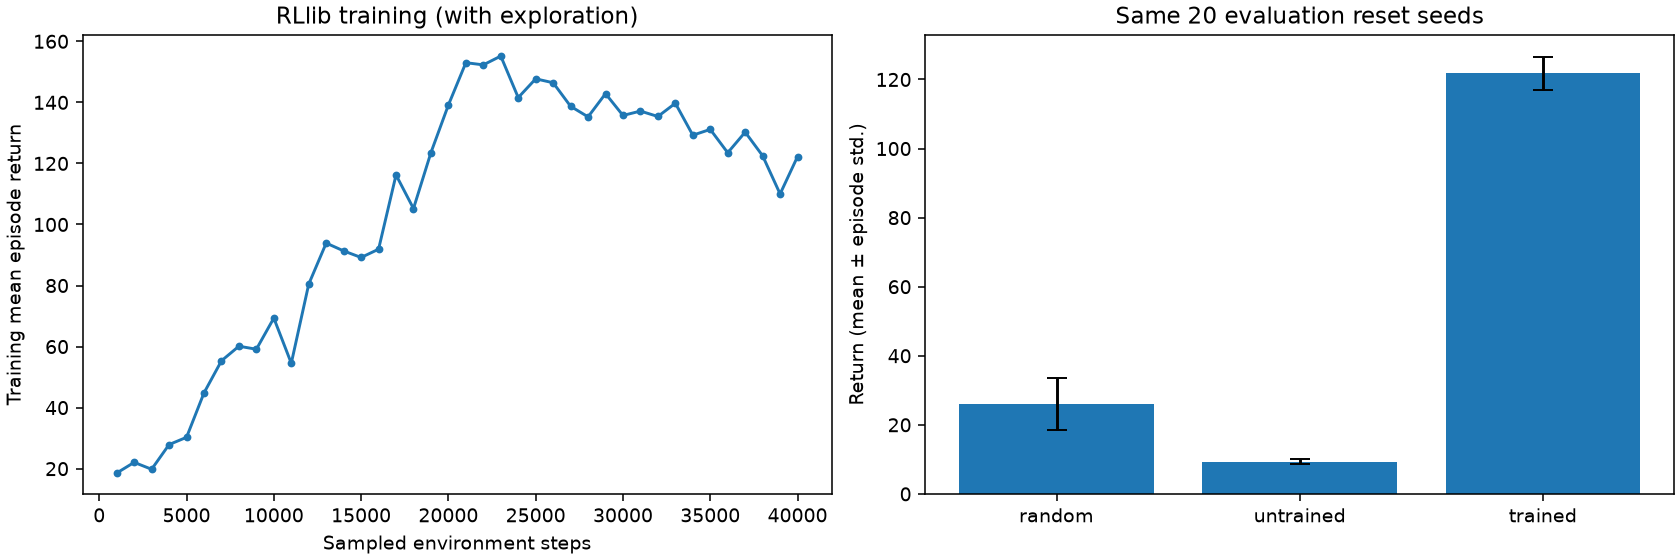

In [5]:
with (OUTPUT / "training_history.csv").open("w", newline="") as stream:
    writer = csv.DictWriter(stream, fieldnames=list(history[0]))
    writer.writeheader()
    writer.writerows(history)
with (OUTPUT / "metrics.csv").open("w", newline="") as stream:
    writer = csv.DictWriter(stream, fieldnames=["policy", *metrics["random"]])
    writer.writeheader()
    for policy, values in metrics.items():
        writer.writerow({"policy": policy, **values})
print(f"{'Policy':12s} {'Mean return':>12s} {'Std return':>12s} {'Mean length':>12s} {'Time limit':>12s}")
for name, values in metrics.items():
    print(f"{name:12s} {values['mean_return']:12.1f} {values['std_return']:12.1f} "
          f"{values['mean_length']:12.1f} {values['time_limit_fraction']:12.0%}")
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].plot([r["sampled_steps"] for r in history],
             [r["training_mean_return"] for r in history], marker=".")
axes[0].set(xlabel="Sampled environment steps", ylabel="Training mean episode return",
            title="RLlib training (with exploration)")
axes[1].bar(list(metrics), [m["mean_return"] for m in metrics.values()],
            yerr=[m["std_return"] for m in metrics.values()], capsize=5)
axes[1].set(ylabel="Return (mean ± episode std.)", title="Same 20 evaluation reset seeds")
fig.savefig(OUTPUT / "rllib_results.png", dpi=140)
plt.close(fig)
display(Image(filename=str(OUTPUT / "rllib_results.png")))

### Watch the frozen policies
These previews use the same initial reset seed and at most 125 frames. The copied modules can run after Ray shuts down. A short clip illustrates behavior; the full evaluation table measures it.

In [6]:
def animate_module(module, *, seed=2026, title="RLlib DQN", max_frames=125):
    env = gym.make("CartPole-v1", render_mode="rgb_array")
    frames = []
    try:
        observation, _ = env.reset(seed=seed)
        frames.append(env.render()[::2, ::2])
        for _ in range(max_frames - 1):
            action = greedy_action(module, observation)
            observation, _, terminated, truncated, _ = env.step(action)
            frames.append(env.render()[::2, ::2])
            if terminated or truncated:
                break
    finally:
        env.close()
    fig, ax = plt.subplots(figsize=(5, 3))
    image = ax.imshow(frames[0])
    ax.axis("off")
    ax.set_title(title)
    def update(i):
        image.set_data(frames[i])
        return (image,)
    animation = FuncAnimation(fig, update, frames=len(frames), interval=40, blit=True)
    html = animation.to_jshtml()
    plt.close(fig)
    return HTML(html)

display(animate_module(initial_module, title="RLlib DQN — before training"))
display(animate_module(trained_module, title="RLlib DQN — after training"))

/opt/venv/lib/python3.12/site-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


## 6. Explain the comparison

1. Which parts of handwritten DQN did RLlib take over? Which parts still belong to Gymnasium?
2. Locate the replay, exploration, target-network, and neural-architecture settings in `config`.
3. Why is a training iteration different from an episode? Why plot sampled steps?
4. Did the RLlib policy improve? Cite the three-policy metrics and episode variability.
5. Why would different returns between the notebooks not prove that one implementation is better? Identify the target-update and replay-update differences.
6. What does scaling to remote environment runners offer, and what overhead might it add for this small task?

**Submit:** the evaluation table, the results plot, your advance prediction, and 3–5 sentences explaining the result. Repeat with multiple training seeds before making broader comparisons.

### References

- [Ray RLlib DQN configuration and source](https://docs.ray.io/en/latest/_modules/ray/rllib/algorithms/dqn/dqn.html)
- [RLlib algorithm configuration](https://docs.ray.io/en/latest/rllib/package_ref/algorithm-config.html)
- [RLlib RLModules and inference](https://docs.ray.io/en/latest/rllib/rl-modules.html)
- [Gymnasium CartPole specification](https://gymnasium.farama.org/environments/classic_control/cart_pole/)

The code targets the repository's pinned Ray 2.59.0. Online documentation may describe a later version.